<a href="https://colab.research.google.com/github/lovkush7/NLP--P/blob/main/cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, MaxPool2D, Conv2D, Flatten
from tensorflow.keras.utils import to_categorical




In [5]:
df = pd.read_csv('mnist_train.csv')
df_test = pd.read_csv('mnist_test.csv')

In [6]:
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,0,0,0,1,1,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,1.0
1,1,0,0,0,0,0,0,0,0,1,...,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,1,0,0,0,0,0,0,0,0,...,0.0,0.0,1.0,0.0,0.0,0.0,2.0,1.0,1.0,1.0
3,3,0,0,0,0,0,1,4,6,6,...,0.0,1.0,0.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0
4,4,2,1,0,3,0,5,0,0,0,...,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
df_test.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,2,4,0,0,2,...,0,0,0,6,0,0,0,4,6,0
2,2,6,0,0,0,1,0,0,0,0,...,1,2,0,6,0,0,1,0,0,3
3,3,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,0,0


In [8]:
df.shape


(23201, 785)

In [11]:
df.isnull().sum()

,0
label,0
1x1,0
1x2,0
1x3,0
1x4,0
...,...
28x24,1
28x25,1
28x26,1
28x27,1


In [13]:
df.fillna(0, inplace=True)

In [14]:
df.isnull().sum()

,0
label,0
1x1,0
1x2,0
1x3,0
1x4,0
...,...
28x24,0
28x25,0
28x26,0
28x27,0


In [16]:
X_train = df.drop('label', axis=1).values
y_train = df['label'].values
X_test = df_test.drop('label', axis=1).values
y_test = df_test['label'].values

In [17]:
X_train = X_train.astype('float32')/255.0
X_test = X_test.astype('float32')/255.0

In [19]:
X_train_img = X_train.reshape(-1, 28,28)
X_test_img = X_test.reshape(-1, 28,28)

In [21]:
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

In [22]:
perceptron = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10, activation='softmax')
])

In [24]:
perceptron.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

In [27]:
from re import VERBOSE
history_per = perceptron.fit(
    X_train_img, y_train_cat,
    validation_data=(X_test_img, y_test_cat),
    epochs=10,
    batch_size=32,
    verbose=1
)

Epoch 1/10
726/726 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.3708 - loss: 2.0145 - val_accuracy: 0.4764 - val_loss: 1.8327
Epoch 2/10
726/726 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5205 - loss: 1.7136 - val_accuracy: 0.5340 - val_loss: 1.6523
Epoch 3/10
726/726 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5529 - loss: 1.5784 - val_accuracy: 0.5508 - val_loss: 1.5613
Epoch 4/10
726/726 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5704 - loss: 1.4963 - val_accuracy: 0.5650 - val_loss: 1.4940
Epoch 5/10
726/726 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5849 - loss: 1.4395 - val_accuracy: 0.5784 - val_loss: 1.4479
Epoch 6/10
726/726 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5945 - loss: 1.3969 - val_accuracy: 0.5856 - val_loss: 1.4120
Epoch 7/10
726/726 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6026 - loss: 1.3627 - val_accuracy: 0.5871 - val_loss: 1.3879
Epoch 8/10
726/726 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6088 - loss: 1.3358 - val_accuracy: 0.

In [28]:
acc_pec = perceptron.evaluate(X_test_img, y_test_cat)[1]
acc_pec

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6088 - loss: 1.3245


0.6087999939918518

In [29]:
ann = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')
])

In [30]:
ann.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [31]:
history_ann = ann.fit(
    X_train_img, y_train_cat,
    validation_data=(X_test_img, y_test_cat),
    epochs=5,
    batch_size=32,
    verbose=1
)

Epoch 1/5
726/726 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8115 - loss: 0.6141 - val_accuracy: 0.9669 - val_loss: 0.1342
Epoch 2/5
726/726 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9814 - loss: 0.0734 - val_accuracy: 0.9806 - val_loss: 0.0639
Epoch 3/5
726/726 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9909 - loss: 0.0339 - val_accuracy: 0.9834 - val_loss: 0.0580
Epoch 4/5
726/726 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9925 - loss: 0.0264 - val_accuracy: 0.9884 - val_loss: 0.0427
Epoch 5/5
726/726 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9956 - loss: 0.0169 - val_accuracy: 0.9894 - val_loss: 0.0335


In [32]:
ann_acc = ann.evaluate(X_test_img, y_test_cat)[1]
ann_acc

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9894 - loss: 0.0335


0.9894000291824341

In [33]:
X_train_cnn = X_train.reshape(-1, 28,28,1)
X_test_cnn = X_test.reshape(-1, 28,28,1)

In [35]:
cnn = Sequential([
    Conv2D(32, kernel_size=(3,3), activation='relu', input_shape=(28,28,1)),
    MaxPool2D(pool_size=(2,2)),
    Conv2D(64, kernel_size=(3,3), activation='relu'),
    MaxPool2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(10, activation='softmax')
])

In [37]:
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [38]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    validation_data=(X_test_cnn, y_test_cat),
    epochs=5,
    batch_size=32,
    verbose=1
)

Epoch 1/5
726/726 ━━━━━━━━━━━━━━━━━━━━ 24s 31ms/step - accuracy: 0.8395 - loss: 0.4818 - val_accuracy: 0.9860 - val_loss: 0.0487
Epoch 2/5
726/726 ━━━━━━━━━━━━━━━━━━━━ 23s 32ms/step - accuracy: 0.9791 - loss: 0.0668 - val_accuracy: 0.9971 - val_loss: 0.0116
Epoch 3/5
726/726 ━━━━━━━━━━━━━━━━━━━━ 23s 32ms/step - accuracy: 0.9866 - loss: 0.0449 - val_accuracy: 0.9993 - val_loss: 0.0030
Epoch 4/5
726/726 ━━━━━━━━━━━━━━━━━━━━ 24s 33ms/step - accuracy: 0.9934 - loss: 0.0203 - val_accuracy: 0.9994 - val_loss: 0.0025
Epoch 5/5
726/726 ━━━━━━━━━━━━━━━━━━━━ 22s 30ms/step - accuracy: 0.9928 - loss: 0.0202 - val_accuracy: 0.9994 - val_loss: 0.0015


In [39]:
cnn_acc = cnn.evaluate(X_test_cnn, y_test_cat)[1]
cnn_acc

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9994 - loss: 0.0015


0.9994000196456909

In [40]:
def plot_tranning(history, title):
  plt.figure(figsize=(10,5))
  plt.plot(history.history['loss'], label='Train loss')
  plt.plot(history.history['val_loss'], label='Validation loss')
  plt.plot(history.history['accuracy'], label='Train accuracy')
  plt.plot(history.history['val_accuracy'], label='Validation accuracy')
  plt.title(title)
  plt.xlabel('Epochs')
  plt.ylabel('Loss/Accuracy')
  plt.legend()
  plt.show()

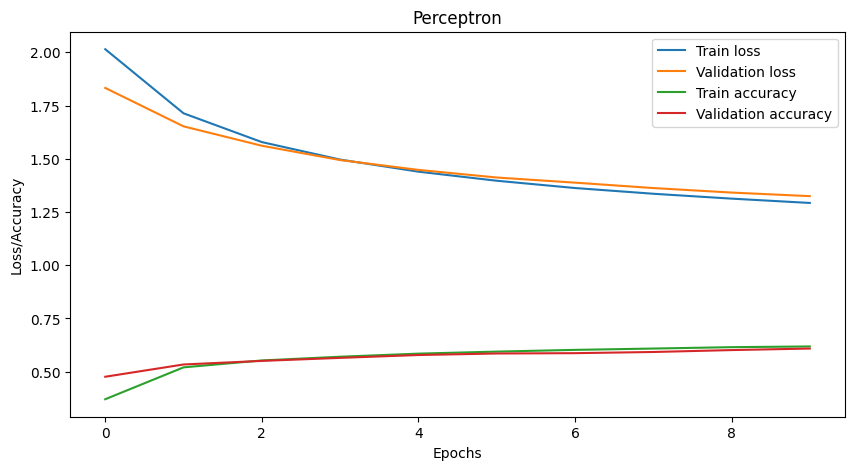

In [41]:
plot_tranning(history_per, 'Perceptron')

In [42]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


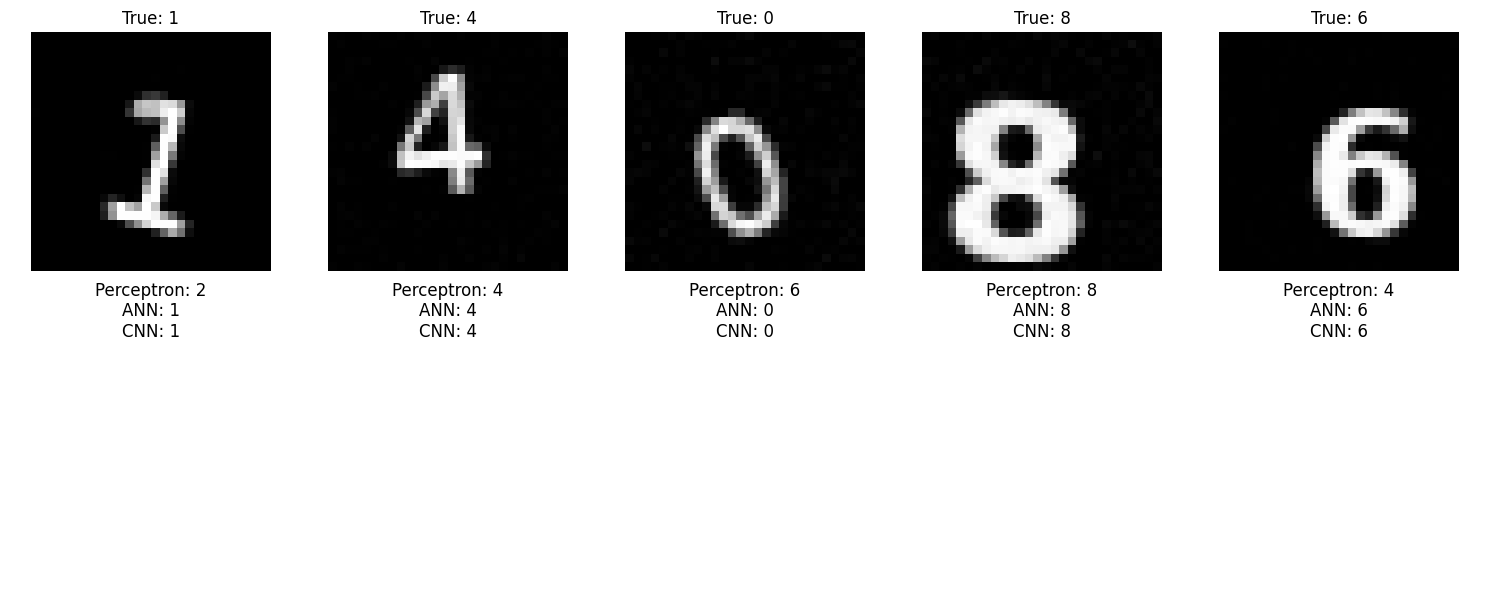

In [43]:

show_side_by_side([perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], X_test_img, X_test_cnn, y_test, 5)